In [90]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [91]:
df = pd.read_csv(r"C:\Users\lenovo\Desktop\spotify\Spotify Music & Artist Analysis.csv")

In [92]:
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [93]:
df.isnull().sum()

Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

In [94]:
df["artists"] = df["artists"].fillna("0")


In [95]:
df["album_name"] = df["album_name"].fillna("0")

In [96]:
df["track_name"] = df["track_name"].fillna("0")

In [97]:
df.isnull().sum()

Unnamed: 0          0
track_id            0
artists             0
album_name          0
track_name          0
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

In [98]:
df[["artists", "track_genre"]] = df[["artists", "track_genre"]].fillna("0")

print(df[["artists", "track_genre"]].isna().sum())

artists        0
track_genre    0
dtype: int64


In [99]:
df["duration_min"] = (df["duration_ms"] / 60_000).round(2)

df[["duration_ms", "duration_min"]].head()

,duration_ms,duration_min
0,230666,3.84
1,149610,2.49
2,210826,3.51
3,201933,3.37
4,198853,3.31


In [100]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Sample dataset with numerical variables
data = {'Age': [25, 28, None, 45, 22], 'Income': [50000, 60000, 75000, None, 40000]}
df = pd.DataFrame(data)

# 1. Fill missing values (Imputation)
imputer = SimpleImputer(strategy='mean')
df[['Age', 'Income']] = imputer.fit_transform(df[['Age', 'Income']])

# 2. Standard Scaling (Mean = 0, Standard Deviation = 1)
scaler = StandardScaler()
df_standard = pd.DataFrame(scaler.fit_transform(df), columns=df.columns)

# 3. Min-Max Scaling (Values scaled between 0 and 1)
minmax_scaler = MinMaxScaler()
df_minmax = pd.DataFrame(minmax_scaler.fit_transform(df), columns=df.columns)

print(df_standard)


        Age    Income
0 -0.626962 -0.540422
1 -0.250785  0.324253
2  0.000000  1.621266
3  1.880887  0.000000
4 -1.003140 -1.405098


In [101]:
from sklearn.preprocessing import MinMaxScaler

# Sample data
data = pd.DataFrame({
    'age': [25, 30, 35, 40],
    'income': [50000, 60000, 80000, 110000]
})

# Initialize the scaler
scaler = MinMaxScaler()

# Fit and transform the data
normalized_data = pd.DataFrame(scaler.fit_transform(data), columns=data.columns)

print(normalized_data)


        age    income
0  0.000000  0.000000
1  0.333333  0.166667
2  0.666667  0.500000
3  1.000000  1.000000


In [102]:
print(df.columns)

Index(['Age', 'Income'], dtype='object')


In [103]:
# Sample data with extreme popularity values
df["popularity"] = pd.DataFrame({"popularity": [1, 5, 12, 50, 1000, 5000000]})

# Use log1p (log(1 + x)) to safely handle 0 values
df["log_popularity"] = np.log1p(df["popularity"])

print(df)


    Age   Income  popularity  log_popularity
0  25.0  50000.0           1        0.693147
1  28.0  60000.0           5        1.791759
2  30.0  75000.0          12        2.564949
3  45.0  56250.0          50        3.931826
4  22.0  40000.0        1000        6.908755


In [104]:
df.head()

,Age,Income,popularity,log_popularity
0,25.0,50000.0,1,0.693147
1,28.0,60000.0,5,1.791759
2,30.0,75000.0,12,2.564949
3,45.0,56250.0,50,3.931826
4,22.0,40000.0,1000,6.908755


In [ ]:
df.head(5)


,popularity,log_popularity
0,1,0.693147
1,5,1.791759
2,12,2.564949
3,50,3.931826
4,1000,6.908755


In [110]:
# which artists have the most popular songs in the dataset? (based on the 'popularity' column)
numeric_cols = [
    "popularity", "duration_ms", "duration_min", "danceability", "energy",
    "key", "loudness", "mode", "speechiness", "acousticness",
    "instrumentalness", "liveness", "valence", "tempo", "time_signature"
]

numeric_cols = [col for col in numeric_cols if col in df.columns]

df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors="coerce")
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())

display(df[numeric_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
popularity,5.0,213.6,440.041248,1.0,5.0,12.0,50.0,1000.0


In [111]:
# does song duration affect populatity?

numeric_cols = [
    "popularity", "duration_ms", "duration_min", "danceability", "energy",
    "key", "loudness", "mode", "speechiness", "acousticness",
    "instrumentalness", "liveness", "valence", "tempo", "time_signature"
]

numeric_cols = [col for col in numeric_cols if col in df.columns]

df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors="coerce")
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())

display(df[numeric_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
popularity,5.0,213.6,440.041248,1.0,5.0,12.0,50.0,1000.0


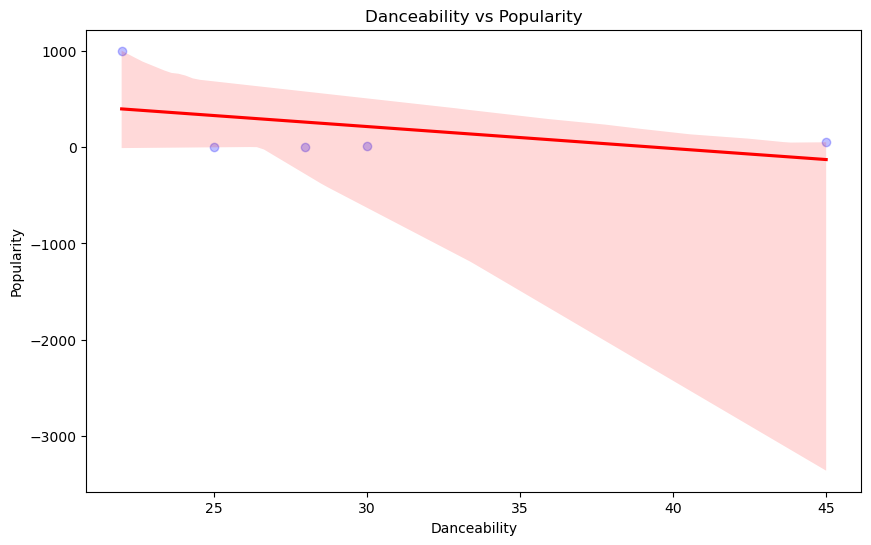

In [ ]:
#  Danceability vs popularity? 

plt.figure(figsize=(10, 6))

x_col = "danceability" if "danceability" in df.columns else ("Age" if "Age" in df.columns else "age")
y_col = "popularity" if "popularity" in df.columns else "log_popularity"

plot_data = df[[x_col, y_col]].dropna()

sns.regplot(
    data=plot_data,
    x=x_col,
    y=y_col,
    scatter_kws={"alpha": 0.25, "color": "blue"},
    line_kws={"color": "red"}
)

plt.title("Danceability vs Popularity")
plt.xlabel("Danceability")
plt.ylabel("Popularity")
plt.show()


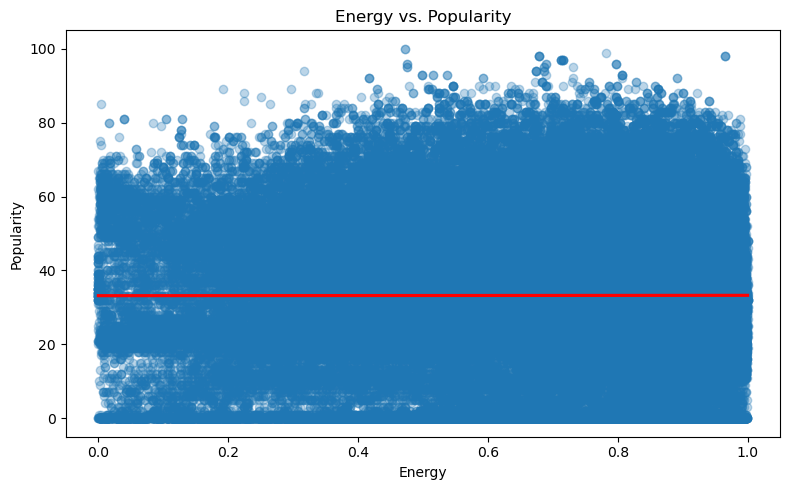

Correlation: 0.0010561362996984968


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

plt.figure(figsize=(8, 5))
# Ensure the Spotify dataframe is available before plotting
if "df" not in globals():
    df = pd.read_csv(r"C:\Users\lenovo\Desktop\spotify\Spotify Music & Artist Analysis.csv")

sns.regplot(
    data=df,
    x="energy",
    y="popularity",
    scatter_kws={"alpha": 0.3},
    line_kws={"color": "red"},
)

plt.title("Energy vs. Popularity")
plt.xlabel("Energy")
plt.ylabel("Popularity")
plt.tight_layout()
plt.show()

# Optional: measure the linear correlation
print("Correlation:", df["energy"].corr(df["popularity"]))

Dataset Shape: (114000, 21)
Columns: ['Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']


C:\Users\lenovo\AppData\Local\Temp\ipykernel_6520\4215091331.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\lenovo\AppData\Local\Temp\ipykernel_6520\4215091331.py:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


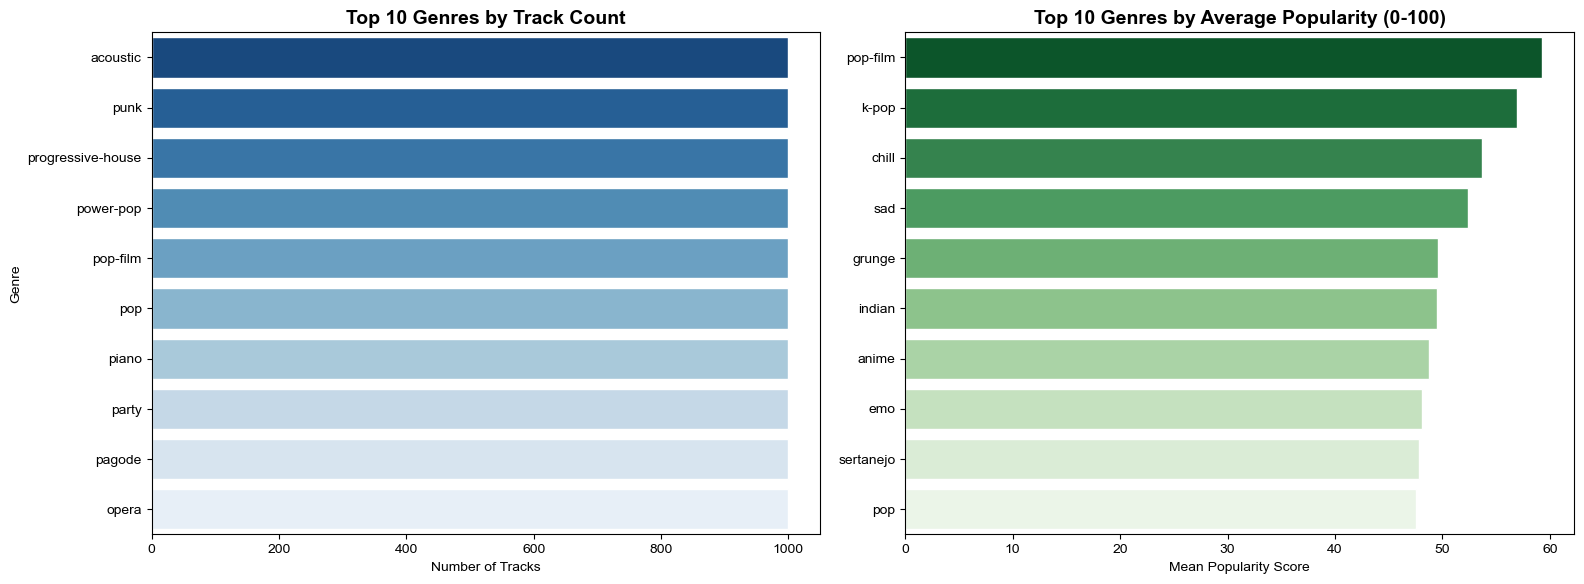


--- Top Genres by Average Popularity ---
track_genre  track_count  mean_popularity
   pop-film         1000           59.283
      k-pop         1000           56.896
      chill         1000           53.651
        sad         1000           52.379
     grunge         1000           49.594
     indian         1000           49.539
      anime         1000           48.772
        emo         1000           48.128
  sertanejo         1000           47.866
        pop         1000           47.576


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load Spotify dataset
# Replace with your dataset path (e.g., Kaggle's Spotify Tracks Dataset)
# Use the dataframe that is already loaded in this notebook instead of trying to read a missing file
if "df" in globals() and isinstance(df, pd.DataFrame):
    pass
else:
    df = pd.read_csv(r"C:\Users\lenovo\Desktop\spotify\Spotify Music & Artist Analysis.csv")

# Inspect primary columns (common Spotify columns: 'track_genre'/'genre', 'popularity')
print("Dataset Shape:", df.shape)
print("Columns:", df.columns.tolist())

# Standardize column names if necessary
genre_col = 'track_genre' if 'track_genre' in df.columns else 'genre'
pop_col = 'popularity'

# -------------------------------------------------------------
# 1. Aggregate dominant genres by Volume and Popularity Score
# -------------------------------------------------------------
genre_stats = df.groupby(genre_col).agg(
    track_count=(pop_col, 'count'),
    mean_popularity=(pop_col, 'mean')
).reset_index()

# Top 10 by track frequency
top_by_count = genre_stats.sort_values(by='track_count', ascending=False).head(10)

# Top 10 by average popularity (minimum 50 tracks to avoid outliers)
top_by_popularity = genre_stats[genre_stats['track_count'] >= 50].sort_values(
    by='mean_popularity', ascending=False
).head(10)

# -------------------------------------------------------------
# 2. Visualization
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.set_theme(style="whitegrid")

# Plot 1: Dominant Genres by Track Volume
sns.barplot(
    data=top_by_count, 
    x='track_count', 
    y=genre_col, 
    palette='Blues_r', 
    ax=axes[0]
)
axes[0].set_title('Top 10 Genres by Track Count', fontsize=14, weight='bold')
axes[0].set_xlabel('Number of Tracks')
axes[0].set_ylabel('Genre')

# Plot 2: Dominant Genres by Average Popularity Score
sns.barplot(
    data=top_by_popularity, 
    x='mean_popularity', 
    y=genre_col, 
    palette='Greens_r', 
    ax=axes[1]
)
axes[1].set_title('Top 10 Genres by Average Popularity (0-100)', fontsize=14, weight='bold')
axes[1].set_xlabel('Mean Popularity Score')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

# Display summary table
print("\n--- Top Genres by Average Popularity ---")
print(top_by_popularity.to_string(index=False))
